# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [20]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearnex import patch_sklearn
patch_sklearn()


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context('notebook')
%matplotlib inline

filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')
data.head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [22]:
# Целевая переменная: 1 = красное вино, 0 = белое
y = (data['color'] == 'red').astype(int)
y.value_counts()


color
0    4898
1    1599
Name: count, dtype: int64

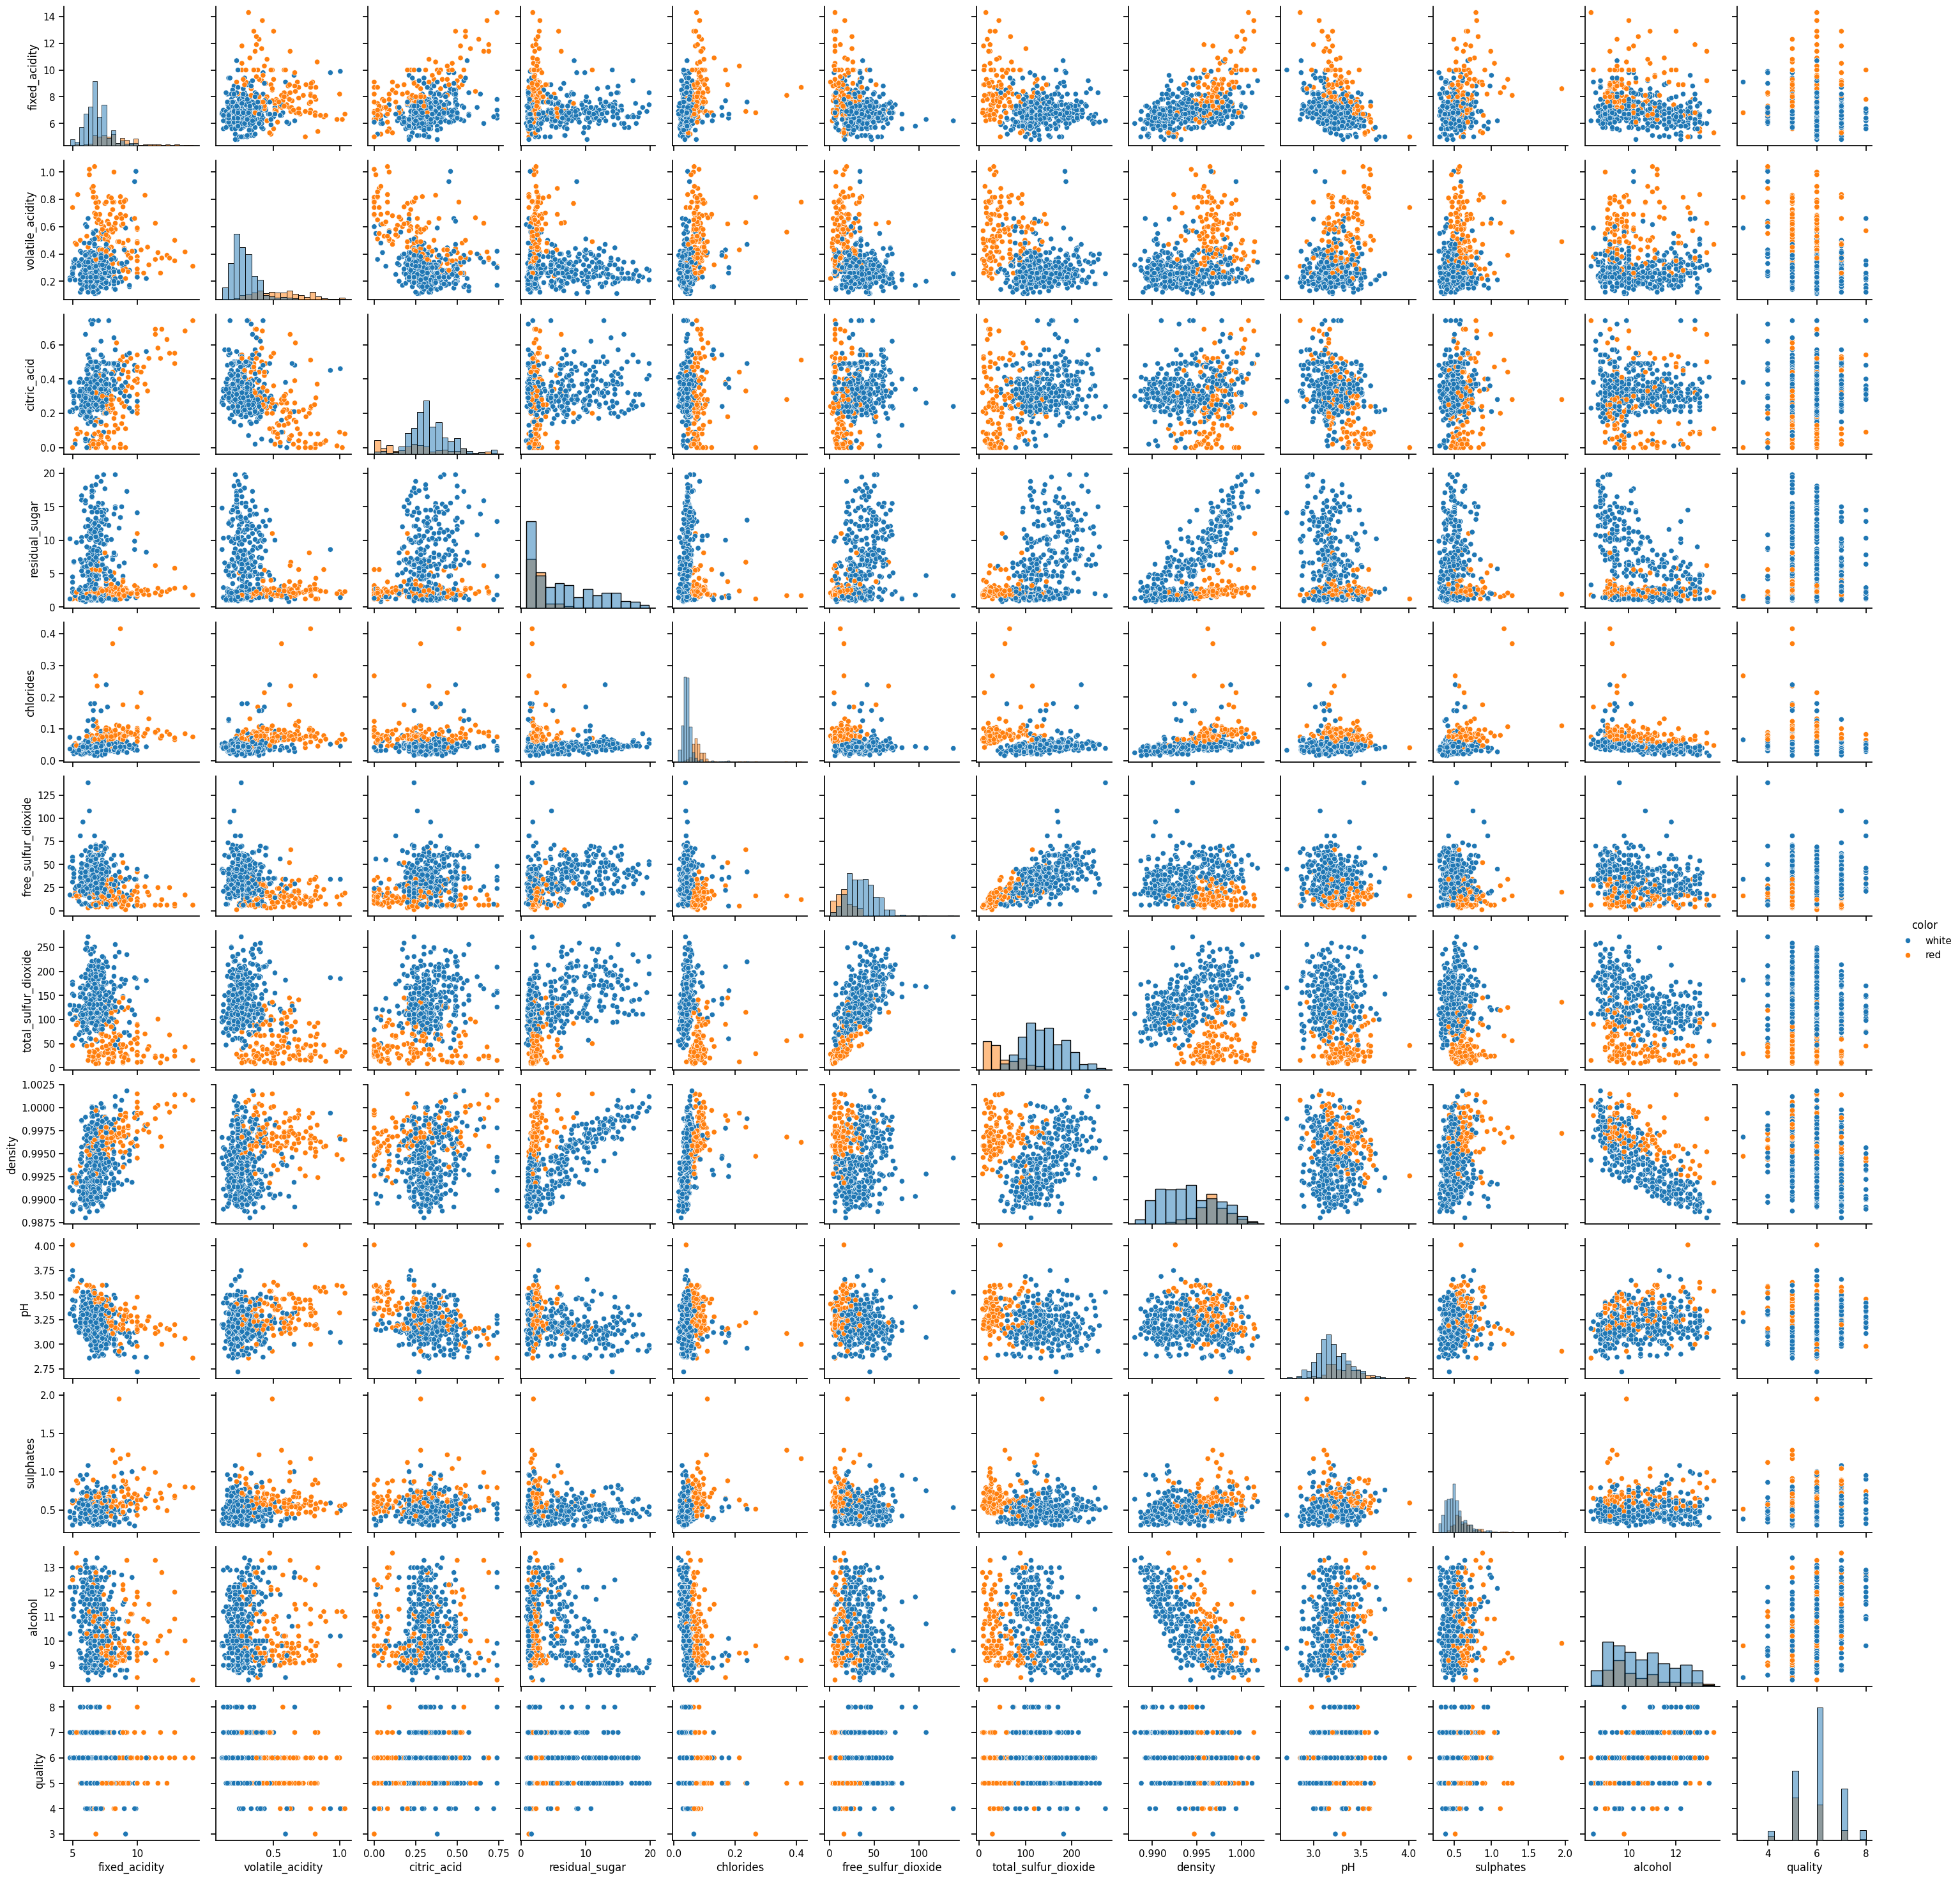

In [23]:
# Парный график (pairplot) по подвыборке, чтобы не перегружать график
sns.pairplot(data.sample(500, random_state=42), hue='color', diag_kind='hist')
plt.show()


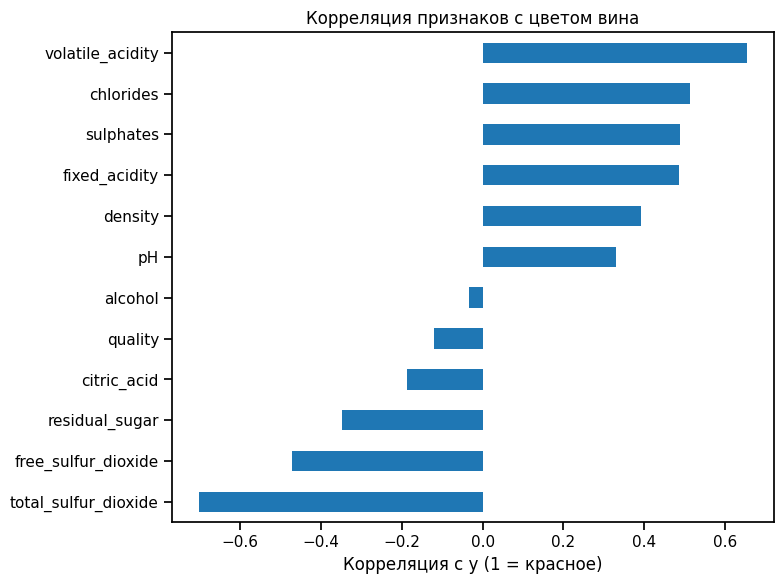

total_sulfur_dioxide   -0.700357
free_sulfur_dioxide    -0.471644
residual_sugar         -0.348821
citric_acid            -0.187397
quality                -0.119323
alcohol                -0.032970
pH                      0.329129
density                 0.390645
fixed_acidity           0.486740
sulphates               0.487218
chlorides               0.512678
volatile_acidity        0.653036
dtype: float64

In [24]:
# Корреляция каждого числового столбца с y
numeric_cols = data.select_dtypes(include=[np.number]).columns
correlations = data[numeric_cols].apply(lambda col: col.corr(y))
correlations = correlations.sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
correlations.plot(kind='barh', ax=ax)
ax.set_xlabel('Корреляция с y (1 = красное)')
ax.set_title('Корреляция признаков с цветом вина')
plt.tight_layout()
plt.show()

correlations


In [25]:
# Выбираем 2 признака с наибольшей корреляцией по модулю
top2 = correlations.abs().sort_values(ascending=False).index[:2]
print('Выбранные признаки:', list(top2))
X = data[top2]
X.head()


Выбранные признаки: ['total_sulfur_dioxide', 'volatile_acidity']


,total_sulfur_dioxide,volatile_acidity
0,34.0,0.70
1,67.0,0.88
2,54.0,0.76
3,60.0,0.28
4,34.0,0.70


In [26]:
# Масштабирование X с помощью MinMaxScaler
scaler = MinMaxScaler()
X_scaled_array = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled_array, columns=top2, index=X.index)
X.head()


,total_sulfur_dioxide,volatile_acidity
0,0.064516,0.413333
1,0.140553,0.533333
2,0.110599,0.453333
3,0.124424,0.133333
4,0.064516,0.413333


## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn. 

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

In [27]:
# Обучаем LinearSVC на X, y
LSVC = LinearSVC(C=1.0, loss='hinge', max_iter=10000, random_state=42)
LSVC.fit(X, y)


,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'hinge'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",10000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed 

In [28]:
# Выбираем 300 случайных образцов для построения графика
np.random.seed(42)
rows = np.random.choice(X.index.values, 300, replace=False)
X_color = X.loc[rows]
y_color = y.loc[rows]

y_color = y_color.map({1: 'red', 0: 'yellow'})
y_color.value_counts()


color
yellow    229
red        71
Name: count, dtype: int64

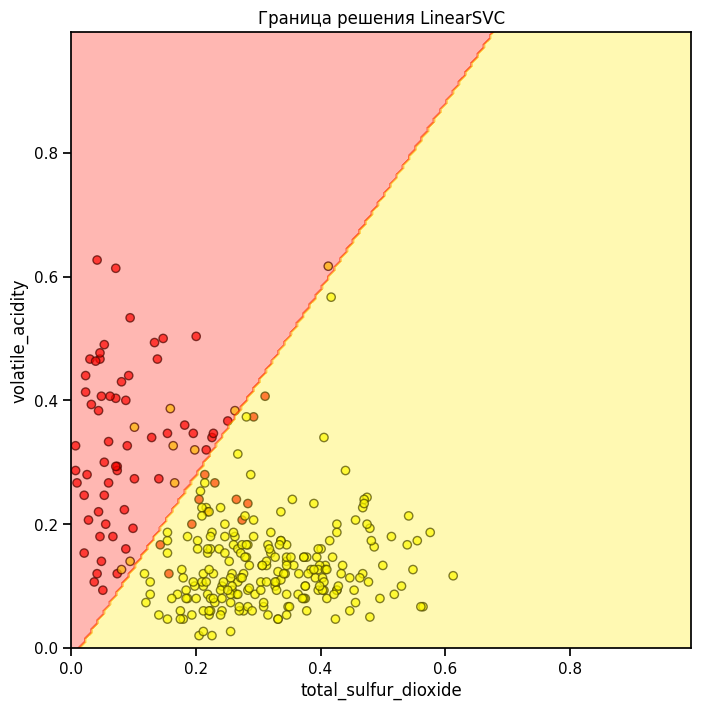

In [29]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.7, edgecolor='k')

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns
y_grid_predictions = LSVC.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

ax.set_xlabel(X.columns[0])
ax.set_ylabel(X.columns[1])
ax.set_title('Граница решения LinearSVC')
plt.show()


## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

In [30]:
def plot_decision_boundary(estimator, X, y, n_samples=300, random_state=42, ax=None, title=None):
    """Обучает estimator на X, y и рисует границу решения с рассеянным графиком."""
    estimator.fit(X, y)

    np.random.seed(random_state)
    rows = np.random.choice(X.index.values, n_samples, replace=False)
    X_color = X.loc[rows]
    y_color = y.loc[rows].map({1: 'red', 0: 'yellow'})

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    xx_ravel = xx.ravel()
    yy_ravel = yy.ravel()
    X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
    X_grid.columns = X.columns
    y_grid_predictions = estimator.predict(X_grid)
    y_grid_predictions = y_grid_predictions.reshape(xx.shape)

    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.7, edgecolor='k')
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    if title:
        ax.set_title(title)
    return estimator


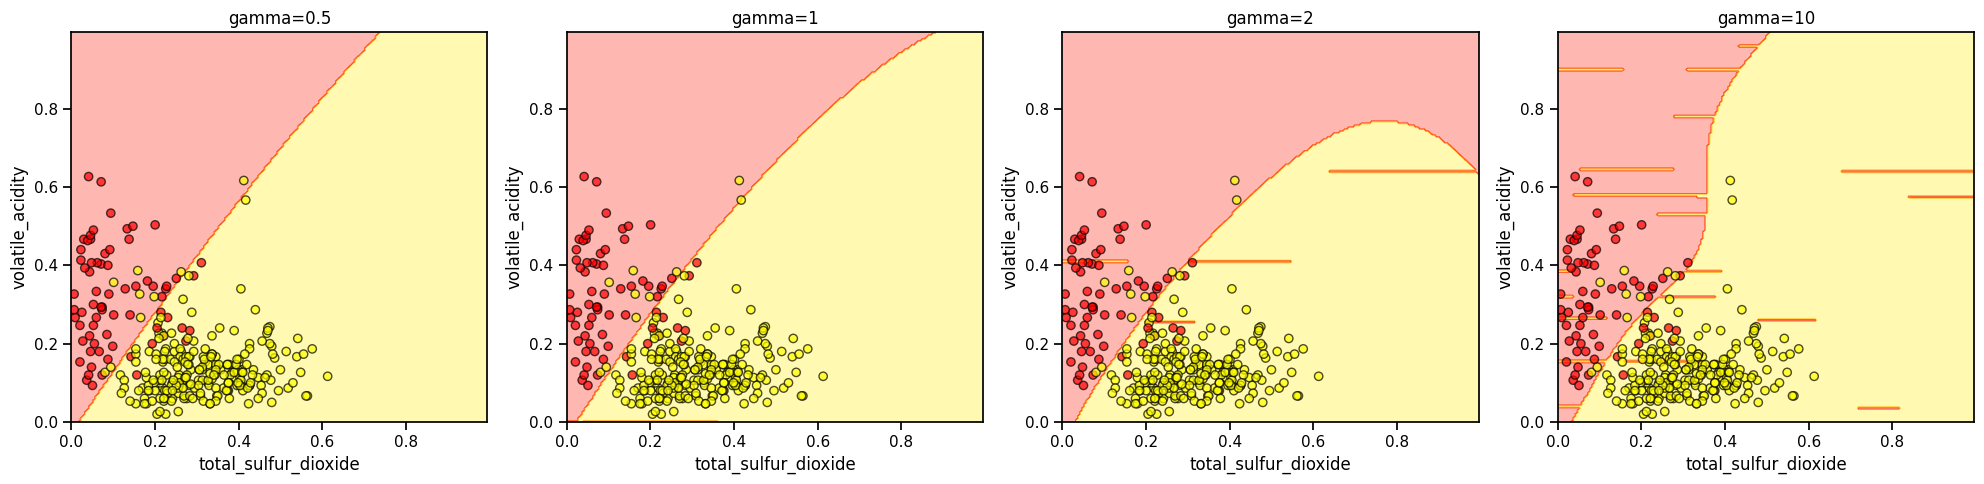

In [31]:
# Варьируем gamma при фиксированном C
gammas = [.5, 1, 2, 10]

fig, axes = plt.subplots(1, len(gammas), figsize=(5 * len(gammas), 5))
for gamma, ax in zip(gammas, axes):
    SVC_Gauss = SVC(kernel='rbf', gamma=gamma, C=1.0, random_state=42)
    plot_decision_boundary(SVC_Gauss, X, y, ax=ax, title=f'gamma={gamma}')
plt.tight_layout()
plt.show()


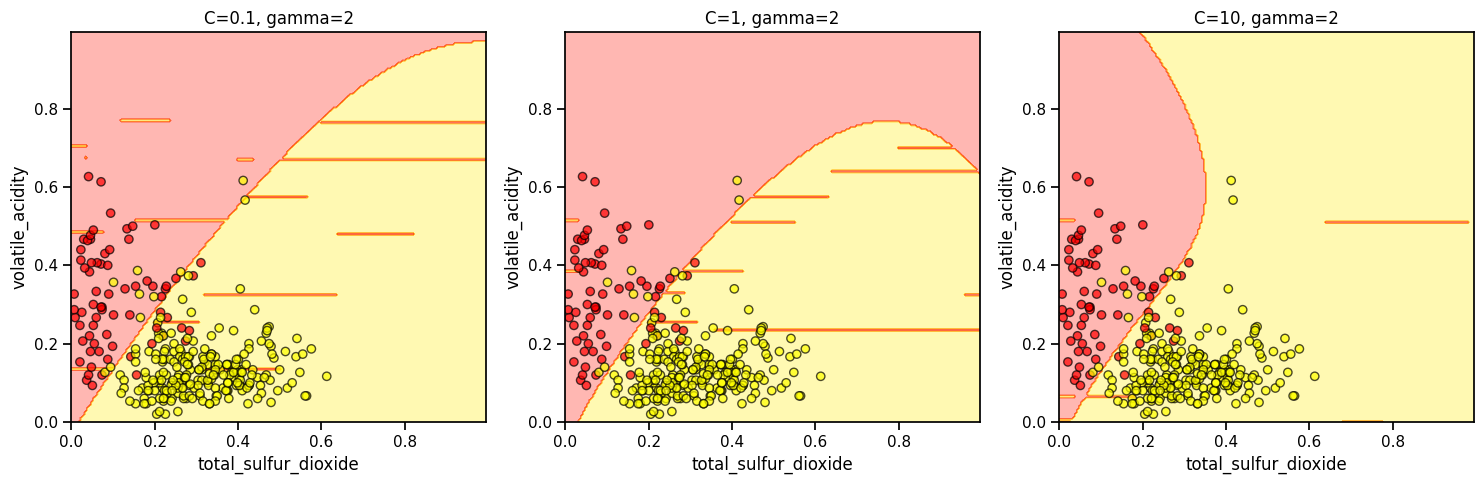

In [32]:
# Варьируем C при фиксированной gamma
Cs = [.1, 1, 10]
gamma_fixed = 2

fig, axes = plt.subplots(1, len(Cs), figsize=(5 * len(Cs), 5))
for C, ax in zip(Cs, axes):
    SVC_Gauss = SVC(kernel='rbf', gamma=gamma_fixed, C=C, random_state=42)
    plot_decision_boundary(SVC_Gauss, X, y, ax=ax, title=f'C={C}, gamma={gamma_fixed}')
plt.tight_layout()
plt.show()


## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [33]:
# Повторная загрузка данных о качестве вина
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')

y = data.color
X = data[[col for col in data.columns if col != 'color']]
X.shape, y.shape


((6497, 12), (6497,))

In [34]:
%%timeit
svc = SVC(kernel='rbf', gamma='scale')
svc.fit(X, y)


149 ms ± 4.6 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [35]:
%%timeit
nystroem = Nystroem(kernel='rbf', random_state=42)
X_transformed = nystroem.fit_transform(X)
sgd = SGDClassifier(max_iter=1000, tol=1e-3)
sgd.fit(X_transformed, y)


60.9 ms ± 5.64 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [36]:
# 5 копий X и y, объединённые вместе
X_big = pd.concat([X] * 5, ignore_index=True)
y_big = pd.concat([y] * 5, ignore_index=True)
X_big.shape, y_big.shape


((32485, 12), (32485,))

In [37]:
%%timeit
svc = SVC(kernel='rbf', gamma='scale')
svc.fit(X_big, y_big)


1.19 s ± 62.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [38]:
%%timeit
nystroem = Nystroem(kernel='rbf', random_state=42)
X_transformed = nystroem.fit_transform(X_big)
sgd = SGDClassifier(max_iter=1000, tol=1e-3)
sgd.fit(X_transformed, y_big)


436 ms ± 21.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
